<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-10/gridworld-bellman.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Value functions on a gridworld

*Deep Learning for Scientific Discovery, Jagiellonian University. Author: Marcin Płodzień.*

### Learning without a teacher

In supervised learning every training input comes with the correct answer. Many problems in science and engineering have no such teacher. A controller that keeps a plasma inside a tokamak, a robot that learns to walk and a lander that has to touch down gently choose actions in sequence, and nobody can tell them the correct action at each moment. They receive a reward instead, a number that says how well things went, and often only at the end. A robot learns that it fell after hundreds of joint commands and has to work out which of them were responsible.

### Agent and environment

Reinforcement learning describes this situation as a loop. The agent observes the state $s_t$ of its environment, chooses an action $a_t$, receives a reward $r_{t+1}$ and finds itself in a new state $s_{t+1}$. It acts through a policy $\pi(a\mid s)$, the probability of choosing $a$ in state $s$. The goal is a policy that collects as much reward as possible over a whole episode.

### Value functions

To improve a policy we first need to measure how good it is. A policy can be good in some situations and poor in others, so the measure is a function of the state. The value $V_\pi(s)$ is the reward the agent can expect to collect when it starts in $s$ and follows $\pi$. Value functions let us compare policies and define the optimal one. The Bellman equations compute them, and temporal-difference learning solves the Bellman equations from experience alone.

### A gridworld

We use a gridworld, a rover on a small terrain, an environment small enough that every value can be computed from the model and drawn as a map, so that every learning method can be checked against the exact answer. We compute values from the model of the environment and find the optimal policy. We then learn the same values without the model, by temporal differences and Q-learning, and look at the dilemma between exploration and exploitation. A final section treats a qubit driven by microwave pulses as a decision problem of the same kind.

The main reference is R. S. Sutton and A. G. Barto, *Reinforcement Learning. An Introduction*, 2nd ed., MIT Press (2018), freely available at [incompleteideas.net/book/the-book-2nd.html](http://incompleteideas.net/book/the-book-2nd.html). All random generators are seeded, so every run gives the same numbers.

> **Running this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*.
> 2. Only `numpy` and `matplotlib` are needed, both pre-installed. The notebook runs in about two minutes on a CPU, most of it in the comparison of the learning methods.
> 3. Run the cells in order. Later cells use variables defined earlier.

In [1]:
# Imports, colours and plotting helpers. The functions only draw, the reinforcement learning happens in the cells after.
import os, json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

plt.rcParams.update({"font.size": 15, "axes.titlesize": 16, "axes.labelsize": 15, "xtick.labelsize": 13,
                     "ytick.labelsize": 13, "legend.fontsize": 13, "figure.titlesize": 17})
UJNavy, UJBlue, UJSky, DSOrange, UJGray = "#002B5C", "#005CA7", "#3E8FD0", "#D35A05", "#5A6270"
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
NUMBERS = {}                                   # numbers quoted in the text, written to a file at the end

def save(fig, name):
    fig.savefig(f"figures/{name}.pdf", bbox_inches="tight")
    fig.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")

def grid(v):
    # a vector over the states as a 5x5 array, NaN on the boulder
    g = np.full((NR, NC), np.nan)
    for s in cells: g[s] = v[idx[s]]
    return g

def draw_board(ax, values=None, policy=None, title="", vmax=10, cmap="RdBu", number_up=False):
    # the terrain, optionally coloured by values (numbers on the tiles) or with the arrows of a deterministic policy
    if values is not None: ax.imshow(grid(values), cmap=cmap, norm=TwoSlopeNorm(0, -vmax, vmax))
    else: ax.imshow(np.zeros((NR, NC)), cmap="Greys", vmin=0, vmax=1)
    for (r, c) in WALLS: ax.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, color=UJGray))
    plain = values is None and policy is None
    for s, lab, col in ((SITE_X, "X", "#1a7f37"), (CRATER, "C", "#b42318"), (START, "S", UJNavy)):
        d = 0.33 if (s == START and not plain) else 0        # keep S clear of the arrow or number on its tile
        ax.text(s[1] - d, s[0] - d, lab, ha="center", va="center", fontsize=17 if plain else 12, color=col, fontweight="bold")
    for s in cells:
        i = idx[s]
        if terminal[i]: continue
        if policy is not None:
            dr, dc = ACTIONS[int(np.argmax(policy[i]))]
            ax.annotate("", xy=(s[1] + .3 * dc, s[0] + .3 * dr), xytext=(s[1] - .3 * dc, s[0] - .3 * dr),
                        arrowprops=dict(arrowstyle="-|>", color=UJNavy if values is None else "k", lw=1.6))
        elif values is not None:
            ax.text(s[1], s[0] - (0.18 if number_up else 0), f"{values[i]:.1f}", ha="center", va="center", fontsize=12)
    ax.set_xticks(np.arange(-.5, NC), minor=True); ax.set_yticks(np.arange(-.5, NR), minor=True)
    ax.grid(which="minor", color="k", lw=0.8); ax.tick_params(which="both", length=0)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title)

def draw_arrows(ax, Q):
    # greedy arrows of Q in the upper half of each tile, above the printed value
    for s in cells:
        i = idx[s]
        if not terminal[i]:
            dr, dc = ACTIONS[int(np.argmax(Q[i]))]
            ax.annotate("", xy=(s[1] + .3 * dc, s[0] + .22 * dr + .25), xytext=(s[1] - .3 * dc, s[0] - .22 * dr + .25),
                        arrowprops=dict(arrowstyle="-|>", color="k", lw=1.2))

def sketch_loop_and_slip():
    # left, the agent-environment loop; right, one tile with the chosen action "up" and the two slips
    fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.35, 1]})
    ax = axs[0]; ax.set_xlim(0, 10); ax.set_ylim(0, 5); ax.axis("off")
    for (x, lab, col) in ((0.3, "agent\npolicy $\\pi(a\\mid s)$", UJBlue), (6.7, "environment\n$p(s'\\mid s,a)$, reward", DSOrange)):
        ax.add_patch(FancyBboxPatch((x, 1.6), 3.0, 1.8, boxstyle="round,pad=0.1", fc="white", ec=col, lw=2.5))
        ax.text(x + 1.5, 2.5, lab, ha="center", va="center", fontsize=15)
    for (x0, x1, y) in ((3.4, 6.6, 3.2), (6.6, 3.4, 1.9)):
        ax.add_patch(FancyArrowPatch((x0, y), (x1, y), arrowstyle="-|>", mutation_scale=22, lw=2, color=UJNavy))
    ax.text(5.0, 3.45, "action $a_t$", ha="center", fontsize=15)
    ax.text(5.0, 0.75, "new state $s_{t+1}$\nreward $r_{t+1}$", ha="center", fontsize=15)
    ax = axs[1]; ax.set_xlim(-1.6, 1.6); ax.set_ylim(-1.6, 1.6); ax.set_aspect("equal"); ax.axis("off")
    for dx in (-1.5, -0.5, 0.5):
        for dy in (-1.5, -0.5, 0.5):
            ax.add_patch(plt.Rectangle((dx, dy), 1, 1, fc="#DCE6F2" if (dx, dy) == (-0.5, -0.5) else "#EEF3F9", ec="k"))
    ax.text(0, -0.3, "agent", ha="center", va="center", fontsize=13, fontweight="bold", color=UJNavy)
    for (dx, dy, p, col) in ((0, 1, "0.8", DSOrange), (1, 0, "0.1", UJGray), (-1, 0, "0.1", UJGray)):
        ax.add_patch(FancyArrowPatch((0.25 * dx, 0.25 * dy + 0.1 * (dy == 0)), (0.85 * dx, 0.85 * dy + 0.1 * (dy == 0)),
                                     arrowstyle="-|>", mutation_scale=18, lw=2.2, color=col))
        ax.text(1.05 * dx, 1.15 * dy + 0.38 * (dy == 0), p, ha="center", va="center", fontsize=14, color=col)
    ax.set_title("chosen action $\\uparrow$ on slippery sand", fontsize=14)
    return fig

def draw_qubit(ax, labels=None, arrows=None, title=""):
    # the six qubit states as a graph, |0> on top, the equator in the middle, |1> at the bottom
    pos = {0: (0, 2), 2: (-2.25, 1), 3: (-0.75, 1), 4: (0.75, 1), 5: (2.25, 1), 1: (0, 0)}
    for i in range(nQ):
        for a in range(nQA):
            j = q_next[i, a]
            if i != Q_TARGET and j != i: ax.plot(*zip(pos[i], pos[j]), color="#c9ced6", lw=1.5, zorder=1)
    for i, a in (arrows or {}).items():
        (x0, y0), (x1, y1) = pos[i], pos[q_next[i, a]]
        ax.annotate("", xy=(x0 + 0.75 * (x1 - x0), y0 + 0.75 * (y1 - y0)), xytext=(x0, y0),
                    arrowprops=dict(arrowstyle="-|>", color=DSOrange, lw=2.2), zorder=2)
        ax.text(x0 + 0.5 * (x1 - x0) - 0.3 * np.sign(x1 - x0), y0 + 0.5 * (y1 - y0),
                "$" + q_pulse_names[a].replace("-", "{-}").replace("+", "{+}") + "$", color=DSOrange, fontsize=15,
                ha="center", va="center", bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none"), zorder=2.5)
    for i, (x, y) in pos.items():
        ax.scatter([x], [y], s=3900, color=UJBlue if i != Q_TARGET else "#1a7f37", zorder=3)
        name = q_names[i].replace("|", "$|$").replace(">", r"$\rangle$")
        ax.text(x, y, name if labels is None else name + "\n" + labels[i], ha="center", va="center", color="white",
                fontsize=15, fontweight="bold", zorder=4)
    ax.set_xlim(-3.1, 3.4); ax.set_ylim(-0.55, 2.6); ax.axis("off"); ax.set_title(title)

## The gridworld as a Markov decision process

A Markov decision process consists of a set of states $\mathcal S$, a set of actions $\mathcal A$, the transition probabilities $p(s'\mid s,a)$ of reaching $s'$ after action $a$ in state $s$, a reward for every transition and a discount factor $\gamma$. The word Markov refers to the assumption that the next state depends only on the current state and action and not on the earlier history. A chess position, the positions and velocities of a lander and the tile of a gridworld are states in this sense, since they contain everything needed to predict what happens next.

Think of a rover on Mars, on a terrain divided into $5\times5$ square tiles. The rover knows on which tile it stands and nothing else. It starts at the landing site S and must drive to the sample site X, where collecting a rock sample earns a reward. A crater C lies close to the sample site, and driving into it ends the mission with a penalty. A boulder blocks the centre tile. The ground is sandy, so the wheels sometimes slip sideways.

| Object | In the gridworld |
|---|---|
| state $s$ | the tile on which the rover stands, written as (row, column) with row 0 at the top. The boulder occupies one tile, so there are 24 states. |
| action $a$ | one of four moves, $\uparrow$, $\rightarrow$, $\downarrow$, $\leftarrow$. The same four actions are available on every tile. |
| transition $p(s'\mid s,a)$ | the rover moves in the chosen direction with probability $0.8$ and slips to one of the two perpendicular directions with probability $0.1$ each. A move into the boulder or off the terrain leaves it on its tile. |
| reward $r$ | $+10$ for reaching the sample site X, $-10$ for driving into the crater C, $0$ for every other step. |
| episode | starts at the landing site S in the lower left corner and ends when the rover reaches X or C. |
| discount $\gamma$ | $0.9$. A reward collected $k$ steps later counts with the weight $0.9^k$. |

At every step the agent looks at its tile, chooses one of the four moves, and the environment answers with the new tile and the reward. That is all the agent ever sees, and its task is to learn which move to choose on each tile so that it reaches X and avoids C. The slip makes the problem interesting. A path that runs right next to the crater is short but risky, because a slip sideways can end in C. A path far from the crater is safe but long, and the discount makes long paths worth less. The value function decides which of the two is better.

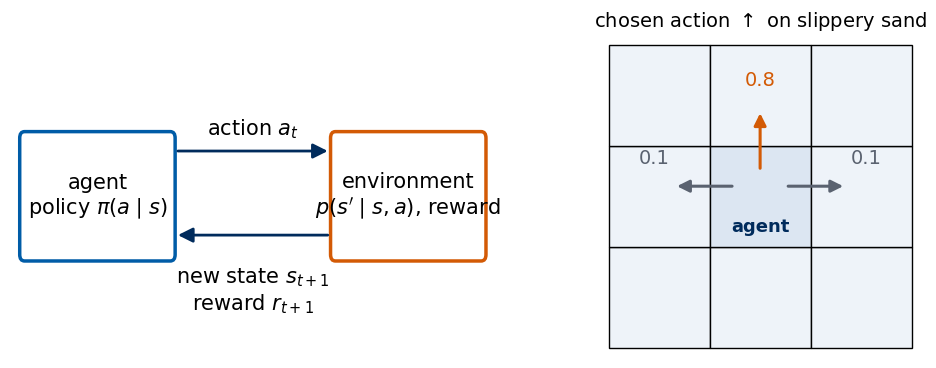

In [2]:
fig = sketch_loop_and_slip()
save(fig, "fig_gw_loop_slip"); plt.show()

The left panel is the loop that every reinforcement learning problem shares. The right panel shows what happens on one tile of the terrain when the rover chooses $\uparrow$. It moves up with probability $0.8$ and slips left or right with probability $0.1$ each. The other three actions behave in the same way, rotated.

The transition probabilities and rewards together are the model of the environment. We store them as arrays `P[s, a, s']` and `R[s, a]`, where `R[s, a]` is the expected reward of action $a$ in state $s$. In most real problems the agent does not know them, and the later sections work without them.

In [3]:
NR, NC = 5, 5
WALLS = {(2, 2)}
SITE_X, CRATER, START = (0, 4), (1, 3), (4, 0)
R_X, R_C = 10.0, -10.0
SLIP = 0.2
ACTIONS = [(-1, 0), (0, 1), (1, 0), (0, -1)]          # up, right, down, left as (row, column) steps
ARROW = ["↑", "→", "↓", "←"]

cells = [(r, c) for r in range(NR) for c in range(NC) if (r, c) not in WALLS]
idx = {s: i for i, s in enumerate(cells)}
nS, nA = len(cells), len(ACTIONS)
terminal = np.array([s in (SITE_X, CRATER) for s in cells])

def move(s, d):
    r, c = s[0] + d[0], s[1] + d[1]
    return s if not (0 <= r < NR and 0 <= c < NC) or (r, c) in WALLS else (r, c)

def reward_of(s2):
    return R_X if s2 == SITE_X else R_C if s2 == CRATER else 0.0

# P[s, a, s'] = p(s'|s,a) and R[s, a] = expected reward of action a in state s
P = np.zeros((nS, nA, nS)); R = np.zeros((nS, nA))
for s in cells:
    i = idx[s]
    for a in range(nA):
        if terminal[i]:
            P[i, a, i] = 1.0
            continue
        for b, prob in ((a, 1 - SLIP), ((a + 1) % 4, SLIP / 2), ((a + 3) % 4, SLIP / 2)):
            s2 = move(s, ACTIONS[b])
            P[i, a, idx[s2]] += prob
            R[i, a] += prob * reward_of(s2)

assert np.allclose(P.sum(-1), 1.0)
print("states:", nS, " actions:", nA)
print("p(s'|s,a) for s = (4,3) and a = up:", {cells[j]: P[idx[(4, 3)], 0, j] for j in np.flatnonzero(P[idx[(4, 3)], 0])})

states: 24  actions: 4
p(s'|s,a) for s = (4,3) and a = up: {(3, 3): np.float64(0.8), (4, 2): np.float64(0.1), (4, 4): np.float64(0.1)}


The printed line is one row $P[s,a,:]$ of the model. From the cell $(4,3)$ the action $\uparrow$ leads up with probability $0.8$ and slips left or right with probability $0.1$ each. Each row of `P` sums to one, as a probability distribution over the next state must.

*Exercise.* Change `SLIP` to $0$ and to $0.5$ and print the same row of the model. Predict which entries change before running the cell.

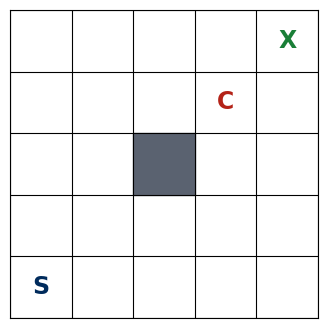

In [4]:
fig, ax = plt.subplots(figsize=(4, 4))
draw_board(ax)
save(fig, "fig_gw_map"); plt.show()

The map shows the terrain. X is the sample site, C the crater, S the landing site and the grey tile the boulder. To see the interaction loop at work we let an agent choose its moves at random and record one episode, each step as the tuple $(s_t,a_t,r_{t+1},s_{t+1})$. Such a list of tuples is all the data a reinforcement learning agent ever receives.

 t   state s    action a   reward r   next state s'
 0   (4, 0)        ←         +0.0     (4, 0)
 1   (4, 0)        →         +0.0     (4, 0)
 2   (4, 0)        ↑         +0.0     (3, 0)
 3   (3, 0)        ↓         +0.0     (3, 0)
 4   (3, 0)        ↑         +0.0     (3, 1)
 5   (3, 1)        ↑         +0.0     (2, 1)
 6   (2, 1)        ←         +0.0     (2, 0)
 7   (2, 0)        →         +0.0     (2, 1)
 8   (2, 1)        ↓         +0.0     (2, 0)
 9   (2, 0)        →         +0.0     (1, 0)
10   (1, 0)        ↓         +0.0     (2, 0)
11   (2, 0)        ←         +0.0     (1, 0)
12   (1, 0)        ←         +0.0     (0, 0)
13   (0, 0)        →         +0.0     (0, 1)
14   (0, 1)        →         +0.0     (0, 2)
15   (0, 2)        ↓         +0.0     (0, 3)
16   (0, 3)        →        +10.0     (0, 4)


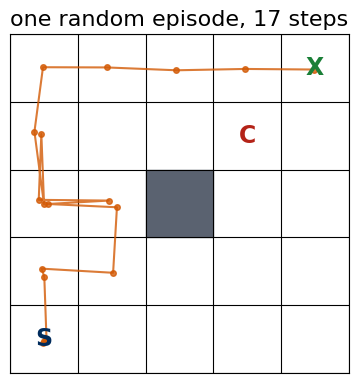

In [5]:
def step(i, a, rng):
    # the environment, one step: sample the next tile from p(s'|s,a) and return it with the reward
    j = rng.choice(nS, p=P[i, a])
    return j, reward_of(cells[j])

rng_demo = np.random.default_rng(20)
i, t, rows = idx[START], 0, []
print(" t   state s    action a   reward r   next state s'")
while not terminal[i] and t < 200:
    a = int(rng_demo.integers(nA))                     # a random move
    j, r = step(i, a, rng_demo)
    print(f"{t:2d}   {str(cells[i]):9s}  {ARROW[a]:^8s}   {r:+6.1f}     {cells[j]}")
    rows.append((t, cells[i], ARROW[a], r, cells[j])); i, t = j, t + 1
NUMBERS["demoLen"] = t

fig, ax = plt.subplots(figsize=(4.4, 4.4))
draw_board(ax)
path = [START] + [row[4] for row in rows]
jit = np.random.default_rng(0).normal(0, 0.06, (2, len(path)))      # small offsets so that repeated tiles stay visible
ax.plot([c for (r, c) in path] + jit[0], [r for (r, c) in path] + jit[1], "-o", color=DSOrange, ms=4, lw=1.5, alpha=0.8)
ax.set_title(f"one random episode, {t} steps")
save(fig, "fig_gw_episode"); plt.show()

The random agent wanders, bumps into the edge of the terrain, slips sideways and reaches X only after many steps. Every reward except the last one is zero, so the information about which moves were good arrives only at the end of the episode. Spreading this late information back over all the earlier states is what the value function and the Bellman equation do.

## Return, policy and value

An episode produces a trajectory $s_0,a_0,r_1,s_1,a_1,r_2,\dots$ and ends when the agent enters X or C. The quantity the agent wants to make large is the discounted return from time $t$,

$$ G_t = r_{t+1}+\gamma r_{t+2}+\gamma^2 r_{t+3}+\dots=\sum_{k=0}^{\infty}\gamma^k r_{t+k+1}, \tag{1}$$

with the discount factor $\gamma=0.9$. A reward that arrives $k$ steps later counts with the weight $\gamma^k$, so a short path to X is worth more than a long one. Splitting off the first term of equation (1) gives the recursion on which all later methods rest,

$$ G_t = r_{t+1}+\gamma\,G_{t+1}. \tag{2}$$

A policy $\pi(a\mid s)$ is the probability that the agent chooses $a$ in state $s$. We compare two deterministic policies. The policy $\pi_{\uparrow}$ walks up to the top row and then right along it. The policy $\pi_{\rightarrow}$ walks right to the last column and then up along it, which takes it past the crater. A third policy, $\pi_{\rm rand}$, picks each action with probability $1/4$.

The return is a random number, because the slips and the policy are random. The value of a state under a policy is its average,

$$ V_{\pi}(s)=\mathbb E_{\pi}\left[G_t\mid s_t=s\right], \tag{3}$$

the expected discounted return when the agent starts in $s$ and follows $\pi$. A single number per policy would not be enough, since a policy can be good in one part of the grid and poor in another.

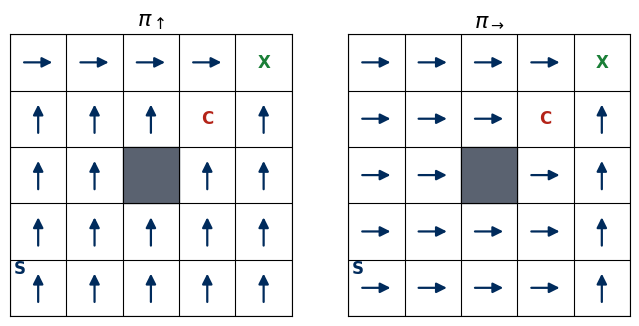

In [6]:
GAMMA = 0.9

def deterministic(rule):
    pi = np.zeros((nS, nA))
    for s in cells: pi[idx[s], rule(s)] = 1.0
    return pi

pi_up = deterministic(lambda s: 1 if s[0] == 0 else 0)            # up, then right along the top row
pi_right = deterministic(lambda s: 0 if s[1] == NC - 1 else 1)    # right, then up along the last column
pi_rand = np.full((nS, nA), 1 / nA)

fig, axs = plt.subplots(1, 2, figsize=(8, 4))
draw_board(axs[0], policy=pi_up, title=r"$\pi_{\uparrow}$")
draw_board(axs[1], policy=pi_right, title=r"$\pi_{\rightarrow}$")
save(fig, "fig_gw_policies"); plt.show()

Equation (3) suggests a direct estimate. We run many episodes from one state, add up the discounted rewards of each and average them. This is the Monte Carlo estimate of the value.

In [7]:
rng = np.random.default_rng(0)

def episode(pi, s, rng, tmax=200):
    # returns the list of (state index, action, reward) of one episode started in cell s
    out, i = [], idx[s]
    for _ in range(tmax):
        if terminal[i]: break
        a = rng.choice(nA, p=pi[i])
        j = rng.choice(nS, p=P[i, a])
        out.append((i, a, reward_of(cells[j]))); i = j
    return out

def mc_return(pi, s, n, rng):
    G = []
    for _ in range(n):
        g = sum(GAMMA**k * r for k, (_, _, r) in enumerate(episode(pi, s, rng)))
        G.append(g)
    return np.array(G)

G_samples = mc_return(pi_up, START, 2000, rng)
print(f"Monte Carlo V_up(S) from 2000 episodes: {G_samples.mean():.3f} ± {G_samples.std(ddof=1)/np.sqrt(len(G_samples)):.3f}")
print(f"spread of single returns: min {G_samples.min():.2f}, max {G_samples.max():.2f}")
NUMBERS["mcVupS"] = round(G_samples.mean(), 2)
NUMBERS["mcVupSerr"] = round(G_samples.std(ddof=1) / np.sqrt(len(G_samples)), 2)

Monte Carlo V_up(S) from 2000 episodes: 2.962 ± 0.063
spread of single returns: min -5.90, max 4.78


The value is an average over trajectories. Each episode from S follows a different path, because the sand is slippery, and collects its own return. Drawing a few of them next to the distribution of all 2000 returns shows what the expectation in equation (3) averages over.

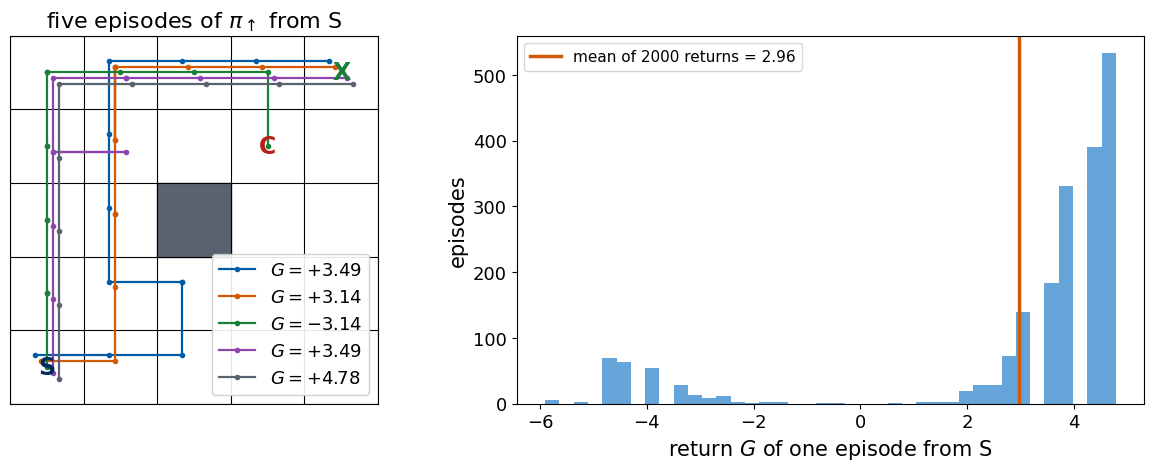

In [8]:
# Five sampled episodes of pi_up from S, each with its return, and the histogram of all 2000 returns.
rng_tr = np.random.default_rng(1)          # a seed in which one of the five episodes ends in the crater
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 1.3]}, layout="constrained")
draw_board(axs[0], title=r"five episodes of $\pi_\uparrow$ from S")
for k, col in enumerate([UJBlue, DSOrange, "#1a7f37", "#8e44ad", UJGray]):
    ep = episode(pi_up, START, rng_tr)
    g = sum(GAMMA**t * r for t, (_, _, r) in enumerate(ep))
    pts = [cells[st] for (st, _, _) in ep] + [SITE_X if ep[-1][2] > 0 else CRATER]    # visited tiles and the final tile
    off = (k - 2) * 0.08
    axs[0].plot([c + off for (r, c) in pts], [r + off for (r, c) in pts], "-o", color=col, ms=3, lw=1.6, label=f"$G={g:+.2f}$")
axs[0].legend(loc="lower right", fontsize=13, framealpha=0.9)
axs[1].hist(G_samples, bins=40, color=UJSky, alpha=0.8)
axs[1].axvline(G_samples.mean(), color=DSOrange, lw=2.5, label=f"mean of 2000 returns = {G_samples.mean():.2f}")
axs[1].set_xlabel("return $G$ of one episode from S"); axs[1].set_ylabel("episodes"); axs[1].legend(loc="upper left", fontsize=11)
save(fig, "fig_gw_returns"); plt.show()

The largest possible return belongs to an episode that reaches X in the shortest eight steps. The reward of the eighth step is discounted seven times, so this return is $0.9^{7}\cdot10\approx4.78$. A slip that pushes the rover off a shortest path usually adds steps and lowers the return, and an episode that ends in the crater returns a negative number. The value $V_{\pi_\uparrow}(S)$ is the mean of this distribution, the orange line.

Single returns scatter widely, because a slip into the crater ends an episode with a negative return. The average over 2000 episodes has a statistical error of a few hundredths. To map the whole terrain this way we would repeat the simulation for every state and every policy. The Bellman equation gives the same numbers from the model, without any sampling.

*Exercise.* Repeat the Monte Carlo estimate with 100 and with 10 000 episodes and check that the statistical error shrinks like $1/\sqrt n$.

## The Bellman expectation equation

We insert the recursion (2) into the definition (3) and use two facts. The expectation is linear, and the future after the first step depends only on the state $s'$ reached, by the Markov property of the environment. Since the environment does not change in time, the expected value of $G_{t+1}$ given $s_{t+1}=s'$ is $V_\pi(s')$ by definition. The first step chooses $a$ with probability $\pi(a\mid s)$ and lands in $s'$ with probability $p(s'\mid s,a)$. Together,

$$ V_{\pi}(s)=\sum_a \pi(a\mid s)\Big[r(s,a)+\gamma\sum_{s'}p(s'\mid s,a)\,V_{\pi}(s')\Big]. \tag{4}$$

Equation (4) is the Bellman expectation equation. It ties the value of a state to the values of its neighbours, one equation for each state. With the policy-averaged transition matrix $P^{\pi}_{ss'}=\sum_a\pi(a\mid s)p(s'\mid s,a)$ and reward vector $r^\pi_s=\sum_a\pi(a\mid s)r(s,a)$ it is a linear system,

$$ V_{\pi}=r^{\pi}+\gamma P^{\pi}V_{\pi}\quad\Longrightarrow\quad V_{\pi}=\left(I-\gamma P^{\pi}\right)^{-1}r^{\pi}, \tag{5}$$

with the identity matrix $I$. The matrix $I-\gamma P^{\pi}$ is invertible for $\gamma<1$, because every eigenvalue of the stochastic matrix $P^{\pi}$ has modulus at most one. The terminal states get the value $0$, since no reward follows them.

In [9]:
def evaluate(pi):
    # solve the linear system (5) for the values of the policy pi
    P_pi = np.einsum("sa,sat->st", pi, P)              # P^pi[s, s'] = sum_a pi(a|s) p(s'|s,a)
    r_pi = (pi * R).sum(1)                             # r^pi[s]   = sum_a pi(a|s) r(s,a)
    P_pi[terminal] = 0.0; r_pi[terminal] = 0.0
    return np.linalg.solve(np.eye(nS) - GAMMA * P_pi, r_pi)

V_up, V_right, V_rand = evaluate(pi_up), evaluate(pi_right), evaluate(pi_rand)
print(f"V_up(S) = {V_up[idx[START]]:.3f},  V_right(S) = {V_right[idx[START]]:.3f},  V_rand(S) = {V_rand[idx[START]]:.3f}")
NUMBERS.update(VupS=round(V_up[idx[START]], 2), VrightS=round(V_right[idx[START]], 2), VrandS=round(V_rand[idx[START]], 2))

# probability h(s) that the random walk from s ends in the crater: system (5) with gamma = 1 and P^pi[s, C] as the reward
P_rand = np.einsum("sa,sat->st", pi_rand, P); P_rand[terminal] = 0.0
h_C = np.linalg.solve(np.eye(nS) - P_rand, P_rand[:, idx[CRATER]])
print(f"random walk from S ends in C with probability {h_C[idx[START]]:.2f} and in X with {1 - h_C[idx[START]]:.2f}")
NUMBERS.update(randEndT=round(h_C[idx[START]], 2), randEndX=round(1 - h_C[idx[START]], 2))

V_up(S) = 2.905,  V_right(S) = 2.905,  V_rand(S) = -0.374
random walk from S ends in C with probability 0.80 and in X with 0.20


The exact $V_{\pi_\uparrow}(S)$ agrees with the Monte Carlo average within its statistical error. The value of the random policy at S is negative. The last line explains why. A rover driving at random from S is absorbed in the crater with probability $h(S)$, which obeys a linear system of the same form as equation (5), with $\gamma=1$ and the one-step probability of entering C in place of the reward. The walk ends in the crater about four times as often as at the sample site, so the average of $+10$ and $-10$ rewards is negative.

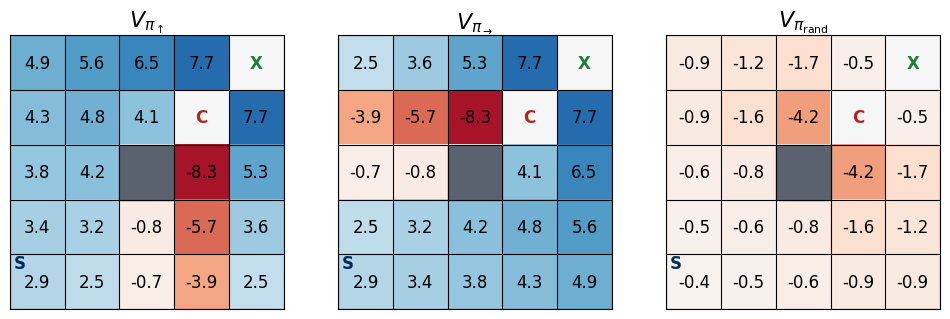

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(12, 4.2))
draw_board(axs[0], V_up, title=r"$V_{\pi_\uparrow}$")
draw_board(axs[1], V_right, title=r"$V_{\pi_\rightarrow}$")
draw_board(axs[2], V_rand, title=r"$V_{\pi_{\rm rand}}$")
save(fig, "fig_gw_values"); plt.show()

Blue tiles have a positive value, red tiles a negative one. Under $\pi_{\uparrow}$ the tiles of the left half have the larger values. The tiles below the crater are poor, because walking up from there leads straight into C. Under $\pi_{\rightarrow}$ the picture is mirrored. The tiles left of the crater in the second row walk right into it, while the bottom row and the last column lead safely to X. The random policy has a negative value almost everywhere, because a random walk meets the crater often. The two hand-made policies have the same value $V(S)$ in the start cell, because the map is symmetric under reflection on the diagonal through S and X, which exchanges the two policies. The value maps differ everywhere else, which shows that one number per policy would hide most of the information.

*Exercise.* Solve the linear system (5) for $\gamma=0.5$ and $\gamma=0.99$ and explain how the maps change.

## Comparing policies

Value functions order policies. We call $\pi$ at least as good as $\pi'$ when it is at least as good in every state,

$$ \pi\ \ge\ \pi' \quad\Longleftrightarrow\quad V_{\pi}(s)\ \ge\ V_{\pi'}(s)\ \ \text{for all } s. \tag{6}$$

This is a partial order. Two policies can be incomparable, each better in a different set of states.

states where pi_up is better: 9  states where pi_right is better: 9


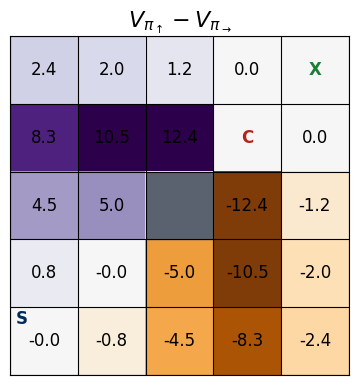

In [11]:
diff = V_up - V_right
n_up_better = int(((diff > 1e-9) & ~terminal).sum()); n_right_better = int(((diff < -1e-9) & ~terminal).sum())
print("states where pi_up is better:", n_up_better, " states where pi_right is better:", n_right_better)
NUMBERS.update(nUpBetter=n_up_better, nRightBetter=n_right_better)

fig, ax = plt.subplots(figsize=(4.4, 4.4))
draw_board(ax, diff, title=r"$V_{\pi_\uparrow}-V_{\pi_\rightarrow}$", cmap="PuOr")
save(fig, "fig_gw_difference"); plt.show()

Neither of the two policies is at least as good as the other. A central result of the theory states that a policy $\pi^*$ exists that is at least as good as every other policy in every state at once. Its value function $V_{\pi^*}(s)=\max_\pi V_\pi(s)$ is the optimal value function, and all optimal policies share it.

## Action values and policy improvement

The value $V_\pi(s)$ scores a state. To decide whether a different action would help we score a state together with a first action. The action value is the expected return when the agent takes $a$ in $s$ and follows $\pi$ afterwards,

$$ Q_{\pi}(s,a)=\mathbb E_\pi\left[G_t\mid s_t=s,\,a_t=a\right]=r(s,a)+\gamma\sum_{s'}p(s'\mid s,a)\,V_{\pi}(s'). \tag{7}$$

Averaging over the first action recovers the state value, $V_\pi(s)=\sum_a\pi(a\mid s)Q_\pi(s,a)$. If some action has $Q_\pi(s,a)>V_\pi(s)$, switching to it in $s$ makes the agent better off. The greedy policy $\pi'(s)=\arg\max_a Q_\pi(s,a)$ is therefore at least as good as $\pi$ in every state, which is the policy improvement theorem. Alternating evaluation and greedy improvement is policy iteration.

On the tile directly below X, $\pi_\uparrow$ moves up. Comparing this action with a move to the left, into the crater, shows what action values measure. The difference $A_\pi(s,a)=Q_\pi(s,a)-V_\pi(s)$ is the advantage of action $a$, how much better it is than the policy's own choice.

In [12]:
s_demo = idx[(1, 4)]                                    # the tile below X
Q_up = R[s_demo] + GAMMA * P[s_demo] @ V_up             # equation (7) for the four actions
for a in range(nA):
    print(f"Q_up((1,4), {ARROW[a]}) = {Q_up[a]:+.2f}   advantage A = Q - V = {Q_up[a] - V_up[s_demo]:+.2f}")
print(f"V_up((1,4)) = {V_up[s_demo]:+.2f}")
NUMBERS.update(QupUp=round(Q_up[0], 2), QupLeft=round(Q_up[3], 2), VupBelowG=round(V_up[s_demo], 2),
               AupLeft=round(Q_up[3] - V_up[s_demo], 2), AupUp=round(Q_up[0] - V_up[s_demo], 2))

Q_up((1,4), ↑) = +7.69   advantage A = Q - V = +0.00
Q_up((1,4), →) = +7.01   advantage A = Q - V = -0.68
Q_up((1,4), ↓) = +3.49   advantage A = Q - V = -4.21
Q_up((1,4), ←) = -6.53   advantage A = Q - V = -14.22
V_up((1,4)) = +7.69


The action that the policy takes, $\uparrow$, has the advantage zero, because for a deterministic policy $V_\pi(s)=Q_\pi(s,\pi(s))$. The move to the left has a large negative advantage, since with probability $0.8$ it ends in the crater. A policy is improved by switching to actions with a positive advantage, which the next cell does on every tile.

In [13]:
def q_from_v(V):
    Q = R + GAMMA * P @ V
    Q[terminal] = 0.0
    return Q

def greedy(Q):
    pi = np.zeros((nS, nA)); pi[np.arange(nS), Q.argmax(1)] = 1.0
    return pi

def improve(Q, pi):
    # greedy step that keeps the current action whenever it is among the maximisers of Q(s, .)
    pi_new = greedy(Q)
    for i in range(nS):
        a = int(pi[i].argmax())
        if Q[i, a] >= Q[i].max() - 1e-9:
            pi_new[i] = 0.0; pi_new[i, a] = 1.0
    return pi_new

pi, history = pi_up.copy(), [V_up[idx[START]]]
for it in range(1, 20):
    pi_new = improve(q_from_v(evaluate(pi)), pi)
    assert (evaluate(pi_new) >= evaluate(pi) - 1e-10).all()   # the improvement theorem, state by state
    if np.array_equal(pi_new, pi): break
    pi = pi_new; history.append(evaluate(pi)[idx[START]])
print("policy iteration from pi_up: stable after", it - 1, "improvements")
print("V(S) along the iterations:", np.round(history, 3))
NUMBERS["piIters"] = it - 1
pi_pi = pi

policy iteration from pi_up: stable after 3 improvements
V(S) along the iterations: [2.905 2.973 3.04  3.052]


No improvement lowered the value of any state, which the assertion checks. The theorem guarantees only this non-strict improvement. In the first improvement the value rises in every non-terminal state except the tiles $(0,3)$ and $(1,4)$ next to X, which keep their values because $\pi_\uparrow$ already acts optimally there. When the current action is among the maximisers of $Q_\pi(s,\cdot)$, the improvement step keeps it, so ties between actions of equal value do not change the policy, and after a few improvements the policy stops changing. A policy that is greedy with respect to its own action values is optimal.

*Exercise.* Start policy iteration from the random policy and count the improvements needed. Check whether the last improvement changes the value of any state or only exchanges actions of equal value.

## The Bellman optimality equation and value iteration

For the optimal policy the average over actions in equation (4) becomes a maximum, since $\pi^*$ puts all its probability on the best action,

$$ V_{\pi^*}(s)=\max_a\Big[r(s,a)+\gamma\sum_{s'}p(s'\mid s,a)\,V_{\pi^*}(s')\Big],\qquad Q_{\pi^*}(s,a)=r(s,a)+\gamma\sum_{s'}p(s'\mid s,a)\max_{a'}Q_{\pi^*}(s',a'). \tag{8}$$

The maximum makes equation (8) nonlinear, so it cannot be solved by one matrix inversion. We read its right-hand side as an operator $\mathcal T$ acting on a value function, $(\mathcal TV)(s)=\max_a[r(s,a)+\gamma\sum_{s'}p(s'\mid s,a)V(s')]$. The optimal values are its fixed point, $V_{\pi^*}=\mathcal TV_{\pi^*}$. The operator shrinks distances by the factor $\gamma$,

$$ \max_s\big|(\mathcal TV)(s)-(\mathcal TU)(s)\big|\ \le\ \gamma\,\max_s\big|V(s)-U(s)\big|, \tag{9}$$

because a maximum changes by at most the largest change of its arguments, and the transition probabilities average the differences. By the Banach fixed-point theorem the iteration $V_{k+1}=\mathcal TV_k$ converges to $V_{\pi^*}$ from any start, with an error that falls at least like $\gamma^k$. This is value iteration.

In [14]:
V = np.zeros(nS); errors = []
for k in range(200):
    V = q_from_v(V).max(1)
V_star = V.copy()
V = np.zeros(nS)
for k in range(80):
    errors.append(np.abs(V - V_star).max())
    V = q_from_v(V).max(1)
Q_star = q_from_v(V_star); pi_star = greedy(Q_star)

print("V*(S) =", round(V_star[idx[START]], 3))
print("V* equals the value of its greedy policy:", np.allclose(evaluate(pi_star), V_star))
print("policy iteration reaches the same values:", np.allclose(evaluate(pi_pi), V_star))
print("V* >= V_up and V* >= V_right in every state:", (V_star >= V_up - 1e-9).all() and (V_star >= V_right - 1e-9).all())
NUMBERS["VstarS"] = round(V_star[idx[START]], 2)

V*(S) = 3.052
V* equals the value of its greedy policy: True
policy iteration reaches the same values: True
V* >= V_up and V* >= V_right in every state: True


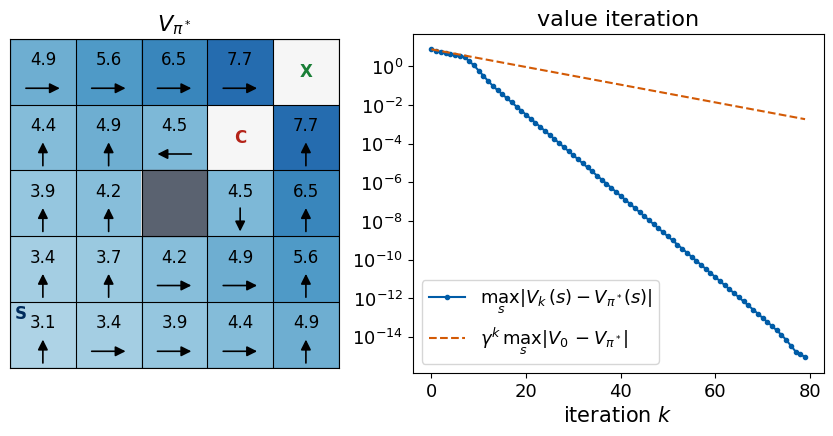

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(10.5, 4.4), gridspec_kw={"width_ratios": [1, 1.25]})
draw_board(axs[0], V_star, title=r"$V_{\pi^*}$", number_up=True); draw_arrows(axs[0], Q_star)
ks = np.arange(len(errors))
axs[1].semilogy(ks, errors, "o-", ms=3, color=UJBlue, label=r"$\max_s|V_k(s)-V_{\pi^*}(s)|$")
axs[1].semilogy(ks, errors[0] * GAMMA**ks, "--", color=DSOrange, label=r"$\gamma^k\,\max_s|V_0-V_{\pi^*}|$")
axs[1].set_xlabel("iteration $k$"); axs[1].legend(); axs[1].set_title("value iteration")
save(fig, "fig_gw_vstar"); plt.show()

The arrows of the optimal policy avoid the crater. From the tile below C the policy steps away from it, and in the second row it walks around the crater through the top row. The error of value iteration stays below the line $\gamma^k$ of equation (9) and falls to machine precision. The optimal values are at least as large as those of both hand-made policies in every state, as the partial order of equation (6) requires. They are larger in most states and equal on the tiles $(0,3)$ and $(1,4)$, where both hand-made policies already take an optimal action.

*Exercise.* Set `SLIP = 0.4`, a slip of $0.2$ to each side. Find the tiles in which the optimal action changes and explain why.

## Learning without a model, temporal difference

Equations (5) and (8) used the arrays `P` and `R`. An agent in a real environment, a robot or a lander, does not know them. It only experiences transitions $(s,a,r,s')$, one at a time, and we want the solution of the Bellman equation from such samples. We combine a running mean, the Bellman equation read as a mean, and the contraction of equation (9).

### A mean learned from samples

Suppose we want the mean $\mu$ of a random number $x$, for example the result of a die, and we see the samples $x_1,x_2,\dots$ one at a time. We keep a single estimate $m$ and after every sample move it a fraction $\alpha$ of the way towards the sample,

$$ m\ \leftarrow\ m+\alpha\,(x_n-m). \tag{10}$$

With $\alpha=1/n$ this reproduces the sample average, since $m_n=m_{n-1}+\frac1n(x_n-m_{n-1})=\frac1n\sum_{k\le n}x_k$. With a small constant $\alpha$ it is a moving average that fluctuates around $\mu$ with a spread that shrinks with $\alpha$. The update never needs the distribution of $x$, only samples.

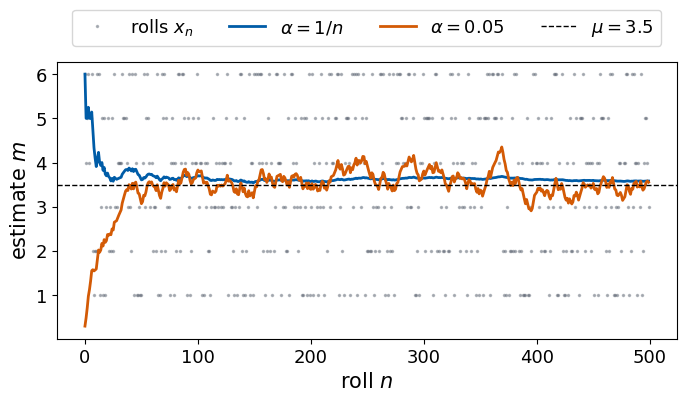

after 500 rolls: alpha=1/n gives 3.582, alpha=0.05 gives 3.554


In [16]:
# Running mean of die rolls, equation (10), with alpha = 1/n and with a constant alpha.
rng_die = np.random.default_rng(7)
rolls = rng_die.integers(1, 7, size=500)
m_avg, m_const, hist_avg, hist_const = 0.0, 0.0, [], []
for n, x in enumerate(rolls, start=1):
    m_avg += (1 / n) * (x - m_avg)        # exact sample average
    m_const += 0.05 * (x - m_const)       # moving average with alpha = 0.05
    hist_avg.append(m_avg); hist_const.append(m_const)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(rolls, ".", color=UJGray, ms=3, alpha=0.4, label="rolls $x_n$")
ax.plot(hist_avg, color=UJBlue, lw=2, label=r"$\alpha=1/n$")
ax.plot(hist_const, color=DSOrange, lw=2, label=r"$\alpha=0.05$")
ax.axhline(3.5, color="k", ls="--", lw=1, label=r"$\mu=3.5$")
ax.set_xlabel("roll $n$"); ax.set_ylabel("estimate $m$"); ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.22))
save(fig, "fig_gw_running_mean"); plt.show()
print(f"after 500 rolls: alpha=1/n gives {m_avg:.3f}, alpha=0.05 gives {m_const:.3f}")

Both estimates settle near $\mu=3.5$ without ever using the probabilities of the faces. The constant step keeps fluctuating, the decreasing step $1/n$ converges.

### The Bellman equation as a mean

The Bellman equation (4) is such a mean. Written with the next reward and state as random variables it reads

$$ V_\pi(s)=\mathbb E\big[\,r_{t+1}+\gamma V_\pi(s_{t+1})\ \big|\ s_t=s\,\big]. \tag{11}$$

One observed transition $(s,a,r,s')$ is one sample of the number inside the expectation, $r+\gamma V(s')$. Applying the running mean (10) to these samples gives the temporal-difference update,

$$ V(s)\ \leftarrow\ V(s)+\alpha\big[\,\underbrace{r+\gamma V(s')}_{\text{TD target}}-V(s)\,\big]. \tag{12}$$

The bracket is the temporal-difference (TD) error $\delta=r+\gamma V(s')-V(s)$. It compares two predictions of the same return, the old estimate $V(s)$ and the one-step-later estimate $r+\gamma V(s')$, which already contains one real reward. The name refers to this difference between predictions made at two successive times.

### The reason the updates converge to the Bellman solution

The target in equation (12) contains $V$ itself, so the update averages towards a target that moves while it learns. Averaging the update over the randomness of the next step makes the mechanism visible. The average of the target is the right-hand side of equation (11) evaluated with the current estimate, which is the Bellman operator $\mathcal T_\pi V$, so on average

$$ V\ \leftarrow\ V+\alpha\,(\mathcal T_\pi V-V)=(1-\alpha)\,V+\alpha\,\mathcal T_\pi V. \tag{13}$$

This is value iteration with damping. Since $\mathcal T_\pi$ is a contraction with factor $\gamma$, as in equation (9), the damped map is a contraction with factor $1-\alpha(1-\gamma)<1$ and converges to the unique fixed point $V=\mathcal T_\pi V$, which is the Bellman equation. The actual updates add zero-mean noise to equation (13), and the running-mean argument removes it when the step size $\alpha_n(s)$ used at the $n$-th visit of state $s$ decreases slowly enough, $\sum_n\alpha_n(s)=\infty$ and $\sum_n\alpha_n(s)^2<\infty$ for every state $s$, the conditions of Robbins and Monro. TD learning is thus value iteration in which the expectation over the next state is replaced by one sample and a small step. The fixed point is the place where the TD error vanishes on average, and that place is the solution of the Bellman equation.

### The value spreads backwards from the sample site

At the start all values are zero, and the only nonzero TD target is the one of the step into X. After the first episode only the tile before X has learned something. The next time the agent passes the tile before that one, its target $r+\gamma V(s')$ contains the new value, and so the value spreads backwards from the sample site, one step per visit. We evaluate the optimal policy with equation (12) and draw the estimate after 1, 10, 100 and 1000 episodes.

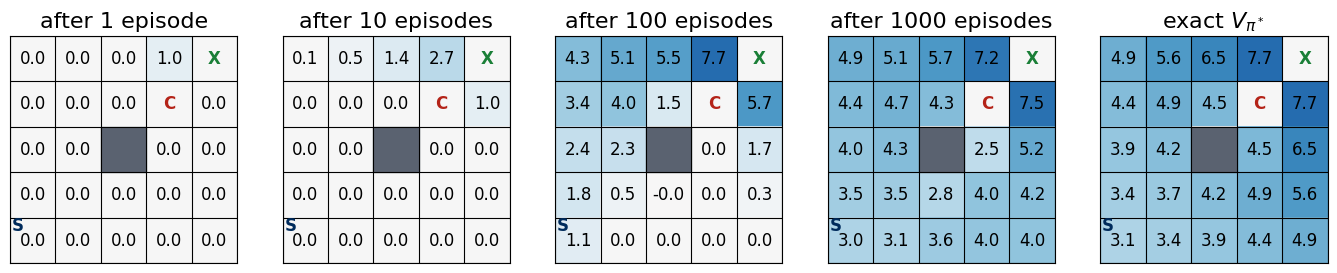

In [17]:
def td0(pi, n_episodes, alpha, rng, V_ref, snapshots=()):
    # TD(0) policy evaluation, equation (12). V_ref is the exact answer, used only to measure the error.
    V = np.zeros(nS); err = []; snaps = {}
    for ep in range(1, n_episodes + 1):
        i = idx[START]
        while not terminal[i]:
            a = rng.choice(nA, p=pi[i])                 # the agent acts
            j = rng.choice(nS, p=P[i, a])               # the environment answers (P is used only to simulate)
            r = reward_of(cells[j])
            target = r + GAMMA * V[j] * (not terminal[j])   # TD target, no future after a terminal tile
            V[i] += alpha * (target - V[i])             # move a fraction alpha towards the target
            i = j
        err.append(np.sqrt(np.mean((V - V_ref)[~terminal]**2)))
        if ep in snapshots: snaps[ep] = V.copy()
    return V, np.array(err), snaps

_, _, snaps = td0(pi_star, 1000, 0.1, np.random.default_rng(2), V_star, snapshots=(1, 10, 100, 1000))
fig, axs = plt.subplots(1, 5, figsize=(17, 3.8))
for ax, ep in zip(axs, (1, 10, 100, 1000)):
    draw_board(ax, snaps[ep], title=f"after {ep} episode" + ("s" if ep > 1 else ""))
draw_board(axs[4], V_star, title=r"exact $V_{\pi^*}$")
save(fig, "fig_gw_td_wave"); plt.show()

After one episode only the last tiles of the path carry value. After ten episodes the value has travelled a few tiles back along the path, and after a hundred it has reached the start. The optimal policy walks up the first column and along the top row, so the value travels back along this path first. Tiles off the path are reached only through slips and fill in later. After a thousand episodes the map is close to the exact values everywhere.

### Monte Carlo and temporal difference

The Monte Carlo method uses the full return $G_t$ of equation (1) as its target,

$$ V(s)\ \leftarrow\ V(s)+\alpha\big[\,G_t-V(s)\,\big]. \tag{14}$$

It does not rely on the current estimate, but it has to wait until the episode ends, and the full return collects the randomness of every later step. The TD target contains the randomness of a single step, at the price of a bias while the estimates are still wrong. We compare both methods on the random policy, whose exact values we know from equation (5), at two step sizes and averaged over ten seeds.

TD(0)        alpha=0.02  RMS error after 1000 episodes: 0.323
Monte Carlo  alpha=0.02  RMS error after 1000 episodes: 0.596
TD(0)        alpha=0.1   RMS error after 1000 episodes: 0.727
Monte Carlo  alpha=0.1   RMS error after 1000 episodes: 1.211


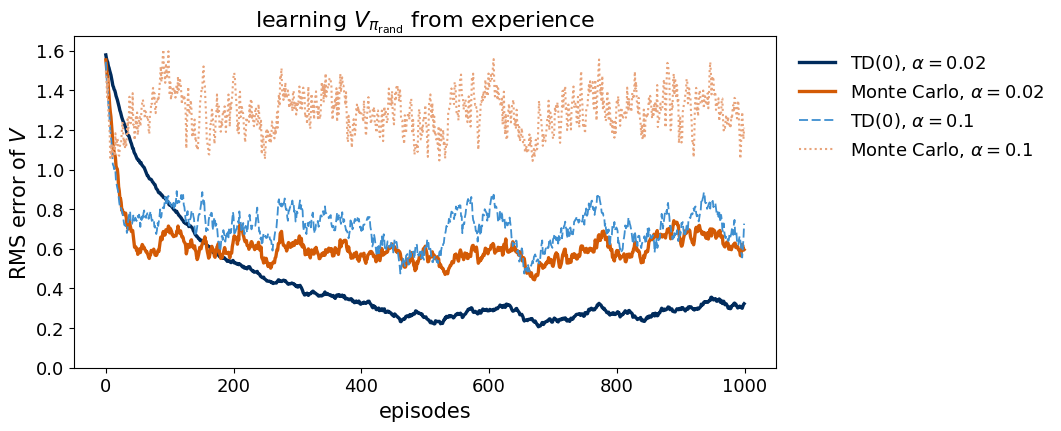

In [18]:
def mc(pi, n_episodes, alpha, rng, V_ref):
    # every-visit Monte Carlo, equation (14): after the episode, move each visited V towards its full return
    V = np.zeros(nS); err = []
    for _ in range(n_episodes):
        G = 0.0
        for (i, a, r) in reversed(episode(pi, START, rng)):   # walk backwards, G_t = r_{t+1} + gamma G_{t+1}
            G = r + GAMMA * G
            V[i] += alpha * (G - V[i])
        err.append(np.sqrt(np.mean((V - V_ref)[~terminal]**2)))
    return V, np.array(err)

curves = {}
for alpha in (0.02, 0.1):
    curves[("TD(0)", alpha)] = np.mean([td0(pi_rand, 1000, alpha, np.random.default_rng(sd), V_rand)[1] for sd in range(10)], 0)
    curves[("Monte Carlo", alpha)] = np.mean([mc(pi_rand, 1000, alpha, np.random.default_rng(sd), V_rand)[1] for sd in range(10)], 0)
for (name, alpha), c in curves.items():
    print(f"{name:12s} alpha={alpha:<5} RMS error after 1000 episodes: {c[-1]:.3f}")
NUMBERS.update(tdErr=round(curves[("TD(0)", 0.02)][-1], 2), mcErr=round(curves[("Monte Carlo", 0.02)][-1], 2),
               tdErrB=round(curves[("TD(0)", 0.1)][-1], 2), mcErrB=round(curves[("Monte Carlo", 0.1)][-1], 2))

fig, ax = plt.subplots(figsize=(10.5, 4.2), layout="constrained")
style = {("TD(0)", 0.02): (UJNavy, "-", 2.4), ("Monte Carlo", 0.02): (DSOrange, "-", 2.4),
         ("TD(0)", 0.1): (UJSky, (0, (5, 2)), 1.3), ("Monte Carlo", 0.1): ("#e8a37a", (0, (1, 1.5)), 1.5)}
for (name, alpha), c in curves.items():
    col, ls, lw = style[(name, alpha)]
    ax.plot(c, color=col, ls=ls, lw=lw, label=fr"{name}, $\alpha={alpha}$")
ax.set_xlabel("episodes"); ax.set_ylabel(r"RMS error of $V$"); ax.set_ylim(0, None)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False); ax.set_title(r"learning $V_{\pi_{\rm rand}}$ from experience")
save(fig, "fig_gw_td_mc"); plt.show()

Both methods approach the exact values without ever reading `P` or `R`, which serve only to simulate the environment. At each of the two step sizes TD(0) ends with a smaller error than Monte Carlo. This is an observation for this problem and these step sizes, in line with the general expectation that the lower variance of the TD target outweighs its bias. The remaining error at the larger step size is the fluctuation of a moving average with a constant step, as for the die. TD also learns after every single step, which matters for long or never-ending tasks.

*Exercise.* Run both methods with $\alpha=0.005$ for 3000 episodes and compare the final errors with those above.

## Q-learning

### Action values instead of state values

To improve the policy without a model we apply the same idea to the optimality equation. Written as means, the two forms of equation (8) differ in the position of the maximum,

$$ V_{\pi^*}(s)=\max_a\,\mathbb E\big[r+\gamma V_{\pi^*}(s')\mid s,a\big],\qquad Q_{\pi^*}(s,a)=\mathbb E\Big[r+\gamma\max_{a'}Q_{\pi^*}(s',a')\ \Big|\ s,a\Big]. \tag{15}$$

For $V_{\pi^*}$ the maximum stands outside the expectation. A single sample cannot estimate a maximum over averages of different actions, and choosing the best action from $V_{\pi^*}$ would again require $p(s'\mid s,a)$. For $Q_{\pi^*}$ the expectation stands outside and runs only over what the environment does after $(s,a)$. The number $r+\gamma\max_{a'}Q(s',a')$ computed from one observed transition is therefore a sample of the right-hand side, and the running mean applies. This gives Q-learning [C. J. C. H. Watkins and P. Dayan, Mach. Learn. **8**, 279 (1992), [doi:10.1007/BF00992698](https://doi.org/10.1007/BF00992698)],

$$ Q(s,a)\ \leftarrow\ Q(s,a)+\alpha\Big[r+\gamma\max_{a'}Q(s',a')-Q(s,a)\Big]. \tag{16}$$

The convergence argument is the one of equation (13), with the optimality operator, which is also a $\gamma$-contraction. It requires that every pair $(s,a)$ keeps being updated.

### Behaviour while learning

The agent chooses its actions with the $\varepsilon$-greedy rule. With probability $\varepsilon$ it takes a random action and otherwise the action with the largest current $Q$. The random actions make sure that every pair $(s,a)$ is visited. The maximum in the target refers to the greedy policy, so the agent learns the values of the greedy policy while it behaves partly at random, which is why Q-learning is called off-policy.

In [19]:
def eps_greedy(q, eps, rng):
    # with probability eps a random action (exploration), otherwise the best known one (exploitation)
    if rng.random() < eps: return int(rng.integers(len(q)))
    return int(rng.choice(np.flatnonzero(q == q.max())))      # ties broken at random

def q_learning(n_episodes, alpha, eps, rng, tmax=200):
    Q = np.zeros((nS, nA)); ret = []
    for _ in range(n_episodes):
        i, G = idx[START], 0.0
        for t in range(tmax):
            if terminal[i]: break
            a = eps_greedy(Q[i], eps, rng)                  # behave epsilon-greedily
            j = rng.choice(nS, p=P[i, a]); r = reward_of(cells[j])   # the environment answers
            target = r + (0.0 if terminal[j] else GAMMA * Q[j].max())  # sample of the right side of (15)
            Q[i, a] += alpha * (target - Q[i, a])           # running mean, equation (16)
            G += GAMMA**t * r; i = j
        ret.append(G)
    return Q, np.array(ret)

Q_learned, ret_q = q_learning(5000, 0.1, 0.1, np.random.default_rng(1))
pi_learned = greedy(Q_learned)
same = int((pi_learned.argmax(1) == pi_star.argmax(1))[~terminal].sum())
print(f"greedy action agrees with the optimal policy in {same} of {int((~terminal).sum())} states")
print("value of the learned greedy policy at S:", round(evaluate(pi_learned)[idx[START]], 3), "  V*(S):", round(V_star[idx[START]], 3))
differ = [cells[i] for i in range(nS) if not terminal[i] and pi_learned[i].argmax() != pi_star[i].argmax()]
for s in differ:
    i = idx[s]
    print(f"tile {s}: learned {ARROW[int(pi_learned[i].argmax())]}, optimal {ARROW[int(pi_star[i].argmax())]}, "
          f"Q* of the two actions {Q_star[i, int(pi_learned[i].argmax())]:.3f} and {Q_star[i, int(pi_star[i].argmax())]:.3f}")
NUMBERS.update(qSame=same, qStates=int((~terminal).sum()), qLearnedS=round(evaluate(pi_learned)[idx[START]], 2))

greedy action agrees with the optimal policy in 20 of 22 states
value of the learned greedy policy at S: 3.025   V*(S): 3.052
tile (3, 3): learned ↓, optimal →, Q* of the two actions 4.027 and 4.863
tile (4, 1): learned ↑, optimal →, Q* of the two actions 3.312 and 3.428


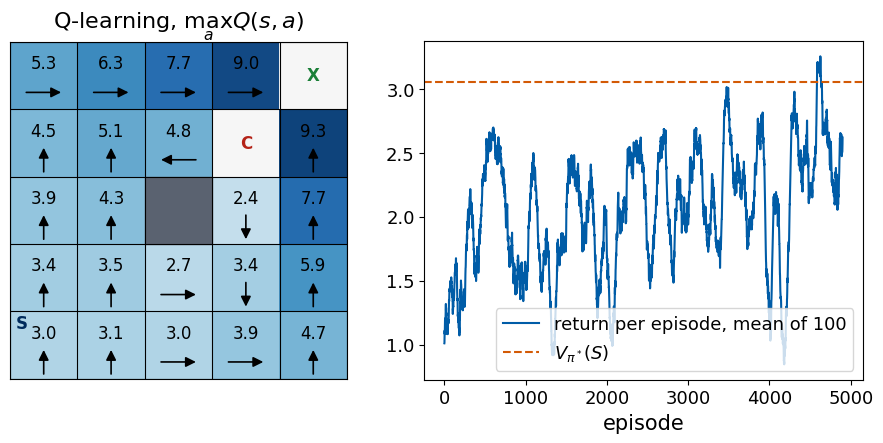

In [20]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={"width_ratios": [1, 1.3]})
draw_board(axs[0], Q_learned.max(1), title=r"Q-learning, $\max_a Q(s,a)$", number_up=True); draw_arrows(axs[0], Q_learned)
w = 100
axs[1].plot(np.convolve(ret_q, np.ones(w) / w, "valid"), color=UJBlue, label="return per episode, mean of 100")
axs[1].axhline(V_star[idx[START]], color=DSOrange, ls="--", label=r"$V_{\pi^*}(S)$")
axs[1].set_xlabel("episode"); axs[1].legend(loc="lower right")
save(fig, "fig_gw_qlearning"); plt.show()

The learned values approach $V_{\pi^*}$ along the path that the agent visits often, and the greedy arrows agree with the optimal policy on 20 of the 22 tiles. On the two other tiles, (3,3) and (4,1), the learned action has a slightly smaller optimal action value than the optimal one, and neither tile lies on the optimal path from S, which climbs the first column. Some learned values near X lie above the exact optimum in this run. A known mechanism contributes to such an excess. With a constant step size each estimate fluctuates around its target, and the maximum over the fluctuating estimates of four actions tends to pick those that are high by chance. The average return stays below $V_{\pi^*}(S)$, because ten percent of the actions are random and occasionally lead into the crater. States far from the usual path are visited rarely and keep less accurate values, which does not harm the policy from the start tile.

*Exercise.* Replace the target of equation (16) by $r+\gamma Q(s',a')$, where $a'$ is the action actually taken next. This is the SARSA algorithm. Compare the learned paths near the crater at $\varepsilon=0.3$.

## Exploration and exploitation

The agent has to try actions to learn their values, and it has to use what it already knows to collect reward. We show the conflict on a second, deterministic grid of $3\times7$ tiles without slips. The agent starts two tiles from a small reward $+1$ and six tiles from a large reward $+10$. Both end the episode. With $\gamma=0.95$ the far reward is worth $10\cdot0.95^{5}\approx7.7$ from the start and the near one $0.95$, so the optimal policy walks to the $+10$.

A purely greedy agent ($\varepsilon=0$) wanders at random only while all its action values are equal. Once it has found the $+1$, the action values along that path are positive and it returns there in every episode, so the far reward is never discovered. With $\varepsilon>0$ the agent keeps taking random actions, and sooner or later a chain of them reaches the $+10$. We run 2000 episodes of Q-learning for 20 seeds at each $\varepsilon$ and check whether the final greedy policy walks to the far reward.

In [21]:
ENR, ENC = 3, 7
E_START, E_NEAR, E_FAR = (2, 2), (2, 0), (0, 6)
E_GAMMA = 0.95

def explore(eps, seed, episodes=2000, alpha=0.5, tmax=100):
    rng = np.random.default_rng(seed)
    Q = np.zeros((ENR, ENC, nA)); ret = np.zeros(episodes); visits = np.zeros((ENR, ENC))
    for ep in range(episodes):
        s, G = E_START, 0.0
        for t in range(tmax):
            visits[s] += 1
            a = eps_greedy(Q[s], eps, rng)
            r_, c_ = s[0] + ACTIONS[a][0], s[1] + ACTIONS[a][1]
            s2 = (r_, c_) if 0 <= r_ < ENR and 0 <= c_ < ENC else s
            r = 1.0 if s2 == E_NEAR else 10.0 if s2 == E_FAR else 0.0
            done = s2 in (E_NEAR, E_FAR)
            Q[s][a] += alpha * (r + (0.0 if done else E_GAMMA * Q[s2].max()) - Q[s][a])
            G += E_GAMMA**t * r; s = s2
            if done: break
        ret[ep] = G
    s = E_START                                         # follow the final greedy policy
    for _ in range(50):
        a = int(np.argmax(Q[s])); r_, c_ = s[0] + ACTIONS[a][0], s[1] + ACTIONS[a][1]
        s = (r_, c_) if 0 <= r_ < ENR and 0 <= c_ < ENC else s
        if s in (E_NEAR, E_FAR): break
    return ret, Q, visits, s == E_FAR

EPSILONS = (0.0, 0.1, 0.3, 0.5)
runs = {eps: [explore(eps, sd) for sd in range(20)] for eps in EPSILONS}
for eps in EPSILONS:
    n_far = sum(r[3] for r in runs[eps])
    print(f"epsilon = {eps}: greedy policy reaches +10 in {n_far} of 20 runs")
    NUMBERS["farEps" + {0.0: "Z", 0.1: "A", 0.3: "C", 0.5: "E"}[eps]] = n_far   # letters: LaTeX macro names cannot contain digits
print("value of the far reward from the start:", round(10 * E_GAMMA**5, 2))

epsilon = 0.0: greedy policy reaches +10 in 0 of 20 runs
epsilon = 0.1: greedy policy reaches +10 in 2 of 20 runs
epsilon = 0.3: greedy policy reaches +10 in 12 of 20 runs
epsilon = 0.5: greedy policy reaches +10 in 20 of 20 runs
value of the far reward from the start: 7.74


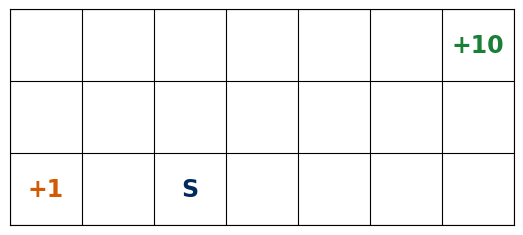

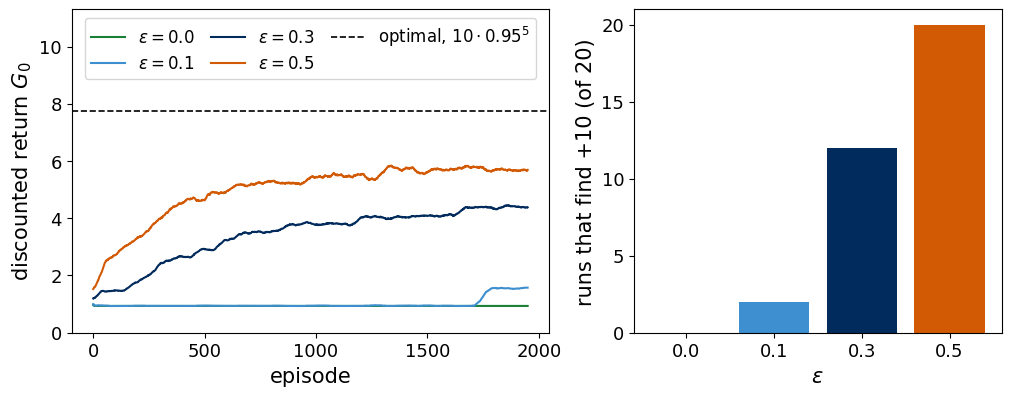

mean discounted return of the last 100 episodes: {0.0: 0.94, 0.1: 1.56, 0.3: 4.39, 0.5: 5.68}


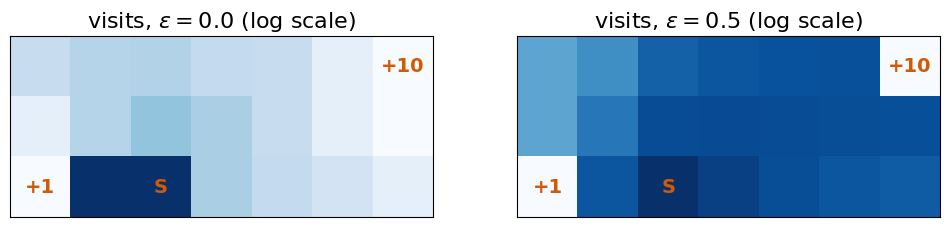

In [22]:
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.imshow(np.zeros((ENR, ENC)), cmap="Greys", vmin=0, vmax=1)
for s, lab, col in ((E_START, "S", UJNavy), (E_NEAR, "+1", DSOrange), (E_FAR, "+10", "#1a7f37")):
    ax.text(s[1], s[0], lab, ha="center", va="center", fontsize=17, fontweight="bold", color=col)
ax.set_xticks(np.arange(-.5, ENC), minor=True); ax.set_yticks(np.arange(-.5, ENR), minor=True)
ax.grid(which="minor", color="k", lw=0.8); ax.tick_params(which="both", length=0); ax.set_xticks([]); ax.set_yticks([])
save(fig, "fig_gw_explore_map"); plt.show()

cols, letter = {0.0: "#1a7f37", 0.1: UJSky, 0.3: UJNavy, 0.5: DSOrange}, {0.0: "Z", 0.1: "A", 0.3: "C", 0.5: "E"}
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})
for eps in EPSILONS:
    m = np.mean([r[0] for r in runs[eps]], 0)                  # mean return per episode over the 20 runs
    axs[0].plot(np.convolve(m, np.ones(50) / 50, "valid"), color=cols[eps], label=fr"$\varepsilon={eps}$")
    NUMBERS["plateau" + letter[eps]] = round(float(m[-100:].mean()), 2)   # mean of the last 100 episodes
axs[0].axhline(10 * E_GAMMA**5, color="k", ls="--", lw=1.2, label=r"optimal, $10\cdot0.95^5$"); axs[0].set_ylim(0, 11.3)
axs[0].set_xlabel("episode"); axs[0].set_ylabel("discounted return $G_0$"); axs[0].legend(loc="upper center", ncol=3, fontsize=12, columnspacing=1.0)
axs[1].bar([str(e) for e in EPSILONS], [sum(r[3] for r in runs[e]) for e in EPSILONS], color=[cols[e] for e in EPSILONS])
axs[1].set_xlabel(r"$\varepsilon$"); axs[1].set_ylabel("runs that find +10 (of 20)")
save(fig, "fig_gw_explore_curves"); plt.show()
print("mean discounted return of the last 100 episodes:", {e: NUMBERS["plateau" + letter[e]] for e in EPSILONS})

fig, axs = plt.subplots(1, 2, figsize=(12, 2.8))               # where the agent goes, first run of each epsilon
for ax, eps in zip(axs, (0.0, 0.5)):
    ax.imshow(np.log10(runs[eps][0][2] + 1), cmap="Blues")
    for (r, c), lab in ((E_START, "S"), (E_NEAR, "+1"), (E_FAR, "+10")):
        ax.text(c, r, lab, ha="center", va="center", fontsize=14, fontweight="bold", color=DSOrange)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(fr"visits, $\varepsilon={eps}$ (log scale)")
save(fig, "fig_gw_explore_visits"); plt.show()

The greedy agent never visits the right part of the grid and settles on the small reward in all runs. Exploration finds the large reward more often the larger $\varepsilon$ is. Exploration has a price, the return lost to random moves after the good path is known. Over the last 100 episodes the discounted return stays below the $10\cdot0.95^5\approx7.74$ of the optimal path, the dashed line, because random moves lengthen the path and sometimes end the episode at the $+1$. Practical agents therefore start with a large $\varepsilon$ and lower it during training.

Tabular methods store one number for every state and action. For a system whose state consists of several real numbers no table exists, and a neural network takes the place of $Q(s,a)$. The update (16) stays the same and becomes the loss function of the network.

## A qubit as a Markov decision process

The same equations describe a small problem of quantum control. A qubit starts in $|0\rangle$, and the agent must bring it to $|1\rangle$ with microwave pulses. Each pulse rotates the state on the Bloch sphere by $90^\circ$ about the $x$ or the $y$ axis, in the positive or negative sense. With probability $0.1$ a pulse fails and leaves the state unchanged, a crude model of control errors. Starting in $|0\rangle$, the state is always one of the six points where the axes cross the Bloch sphere, $|0\rangle$ and $|1\rangle$ at the poles and $|\pm\rangle$ and $|{\pm i}\rangle$ on the equator.

| Object | For the qubit |
|---|---|
| state $s$ | one of the six states $|0\rangle,|1\rangle,|+\rangle,|-\rangle,|{+i}\rangle,|{-i}\rangle$ |
| action $a$ | one of four pulses $X{+}$, $X{-}$, $Y{+}$, $Y{-}$, a rotation by $\pm90^\circ$ about $x$ or about $y$ |
| transition $p(s'\mid s,a)$ | the rotated state with probability $0.9$, the same state with probability $0.1$ |
| reward $r$ | $+1$ when the qubit reaches $|1\rangle$, which ends the episode, $0$ otherwise |
| discount $\gamma$ | $0.9$, so fewer pulses are better |

The rotated states follow from the geometry of the Bloch sphere. A pulse about the axis on which the state lies does nothing, so from $|\pm\rangle$ the $x$ pulses are wasted and from $|{\pm i}\rangle$ the $y$ pulses are. From $|0\rangle$ every pulse leads to the equator, and from each equator state exactly one pulse leads to $|1\rangle$.

The problem is small enough to solve the optimality equation (8) analytically. The target $|1\rangle$ is terminal, so its value is $0$. By symmetry the four equator states have the same value $v_e$, and $|0\rangle$ has the value $v_0$. From an equator state the best pulse reaches $|1\rangle$ with probability $0.9$ and reward $1$ and fails with probability $0.1$. From $|0\rangle$ every pulse leads to the equator with probability $0.9$ and no reward. Hence

$$ v_e=0.9+0.1\,\gamma\,v_e\ \Rightarrow\ v_e=\frac{0.9}{1-0.1\gamma},\qquad v_0=0.9\,\gamma\,v_e+0.1\,\gamma\,v_0\ \Rightarrow\ v_0=\frac{0.9\,\gamma\,v_e}{1-0.1\gamma}. \tag{17}$$

We check these values with value iteration and compare them with the policy of random pulses, evaluated with the linear system (5).

value iteration: V*(|0>) = 0.8803, V*(equator) = [0.989 0.989 0.989 0.989]
equation (17):   V*(|0>) = 0.8803, V*(equator) = 0.9890
random pulses:   V(|0>) = 0.6167, V(equator) = 0.6928


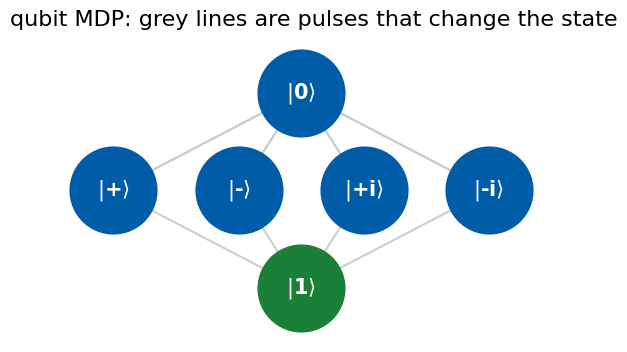

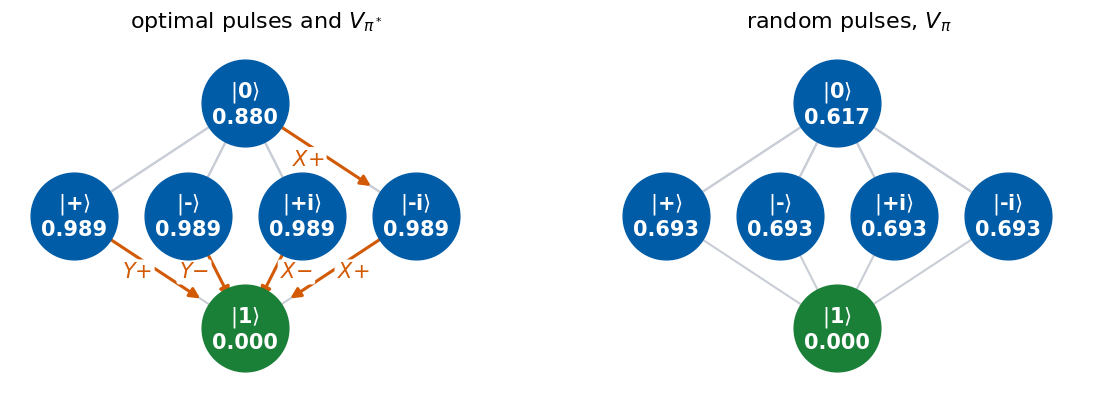

In [23]:
q_names = ["|0>", "|1>", "|+>", "|->", "|+i>", "|-i>"]
q_pulse_names = ["X+", "X-", "Y+", "Y-"]
nQ, nQA, Q_TARGET, Q_FAIL, Q_GAMMA = 6, 4, 1, 0.1, 0.9
# state reached after a successful pulse, one row per state, columns X+, X-, Y+, Y- (the row of |1> is never used)
q_next = np.array([[5, 4, 2, 3], [1, 1, 1, 1], [2, 2, 1, 0], [3, 3, 0, 1], [0, 1, 4, 4], [1, 0, 5, 5]])
P_q = np.zeros((nQ, nQA, nQ)); R_q = np.zeros((nQ, nQA))
for i in range(nQ):
    if i == Q_TARGET: continue                             # |1> is terminal
    for a in range(nQA):
        P_q[i, a, q_next[i, a]] += 1 - Q_FAIL; P_q[i, a, i] += Q_FAIL
        R_q[i, a] = (1 - Q_FAIL) * (q_next[i, a] == Q_TARGET)

V_q = np.zeros(nQ)
for k in range(300):                                       # value iteration
    V_q = (R_q + Q_GAMMA * P_q @ V_q).max(1)
Q_q = R_q + Q_GAMMA * P_q @ V_q
v_e = 0.9 / (1 - 0.1 * Q_GAMMA); v_0 = 0.9 * Q_GAMMA * v_e / (1 - 0.1 * Q_GAMMA)
print(f"value iteration: V*(|0>) = {V_q[0]:.4f}, V*(equator) = {V_q[2:].round(4)}")
print(f"equation (17):   V*(|0>) = {v_0:.4f}, V*(equator) = {v_e:.4f}")
keep = np.arange(nQ) != Q_TARGET                           # random pulses, linear system (5) on the non-terminal states
V_rq = np.zeros(nQ)
V_rq[keep] = np.linalg.solve(np.eye(keep.sum()) - Q_GAMMA * P_q.mean(1)[np.ix_(keep, keep)], R_q.mean(1)[keep])
print(f"random pulses:   V(|0>) = {V_rq[0]:.4f}, V(equator) = {V_rq[2]:.4f}")
NUMBERS.update(qbVstarEq=round(V_q[2], 3), qbVstarZero=round(V_q[0], 3), qbVrandEq=round(V_rq[2], 3), qbVrandZero=round(V_rq[0], 3))

fig, ax = plt.subplots(figsize=(7, 4))
draw_qubit(ax, title="qubit MDP: grey lines are pulses that change the state")
save(fig, "fig_qb_mdp"); plt.show()
fig, axs = plt.subplots(1, 2, figsize=(14, 4.6))
draw_qubit(axs[0], labels={i: f"{V_q[i]:.3f}" for i in range(nQ)}, arrows={i: int(np.argmax(Q_q[i])) for i in range(nQ) if i != Q_TARGET},
           title=r"optimal pulses and $V_{\pi^*}$")
draw_qubit(axs[1], labels={i: f"{V_rq[i]:.3f}" for i in range(nQ)}, title=r"random pulses, $V_\pi$")
save(fig, "fig_qb_values"); plt.show()

Value iteration reproduces equation (17). From $|0\rangle$ all four pulses are equally good, since each leads to the equator, and the arrow shows one of them. From each equator state only the pulse that rotates towards $|1\rangle$ is optimal. The optimal policy is the $\pi$ pulse a physicist would apply, and the discount turns the number of pulses into a lower value. Random pulses waste time on pulses that do nothing or lead back to $|0\rangle$, and their values are much lower.

*Exercise.* Raise the failure probability to $0.5$ and recompute $v_e$ and $v_0$ from equation (17).

In [24]:
# Write the numbers quoted in the text, and the first and last steps of the random episode, to files used for typesetting.
with open("results/numbers_gridworld.json", "w") as f: json.dump(NUMBERS, f, indent=1)
with open("results/nb_numbers_gridworld.tex", "w") as f:            # LaTeX macros such as \gwVupS
    for k, v in NUMBERS.items():
        f.write(f"\\newcommand{{\\gw{k}}}{{{v:.2f}}}\n" if k in ("tdErr", "mcErr", "tdErrB", "mcErrB") else f"\\newcommand{{\\gw{k}}}{{{v}}}\n")
tile = lambda c: "X" if c == SITE_X else "C" if c == CRATER else f"({c[0]},{c[1]})"
arrow_tex = {"↑": r"$\uparrow$", "→": r"$\rightarrow$", "↓": r"$\downarrow$", "←": r"$\leftarrow$"}
with open("results/gw_episode_table.tex", "w") as f:
    for k, (tt, s0, aa, rr, s1) in enumerate(rows):
        if k == 4: f.write(r"$\vdots$ & & & $\vdots$ & \\" + "\n")
        if k < 4 or k >= len(rows) - 2: f.write(f"{tt} & {tile(s0)} & {arrow_tex[aa]} & ${rr:+.0f}$ & {tile(s1)} \\\\\n")
print(NUMBERS)

{'demoLen': 17, 'mcVupS': np.float64(2.96), 'mcVupSerr': np.float64(0.06), 'VupS': np.float64(2.9), 'VrightS': np.float64(2.9), 'VrandS': np.float64(-0.37), 'randEndT': np.float64(0.8), 'randEndX': np.float64(0.2), 'nUpBetter': 9, 'nRightBetter': 9, 'QupUp': np.float64(7.69), 'QupLeft': np.float64(-6.53), 'VupBelowG': np.float64(7.69), 'AupLeft': np.float64(-14.22), 'AupUp': np.float64(0.0), 'piIters': 3, 'VstarS': np.float64(3.05), 'tdErr': np.float64(0.32), 'mcErr': np.float64(0.6), 'tdErrB': np.float64(0.73), 'mcErrB': np.float64(1.21), 'qSame': 20, 'qStates': 22, 'qLearnedS': np.float64(3.03), 'farEpsZ': 0, 'farEpsA': 2, 'farEpsC': 12, 'farEpsE': 20, 'plateauZ': 0.94, 'plateauA': 1.56, 'plateauC': 4.39, 'plateauE': 5.68, 'qbVstarEq': np.float64(0.989), 'qbVstarZero': np.float64(0.88), 'qbVrandEq': np.float64(0.693), 'qbVrandZero': np.float64(0.617)}
